In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

warnings.filterwarnings('ignore')

In [5]:
data = pd.read_excel('insurance_data.xlsx')

In [12]:
data.shape

(30, 7)

In [13]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.48200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


# EDA

In [14]:
data.shape

(30, 7)

In [15]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.48200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [16]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
25,59,female,27.720,3,no,southeast,14001.13380
26,63,female,23.085,0,no,northeast,14451.83515
27,55,female,32.775,2,no,northwest,12268.63225
28,23,male,17.385,1,no,northwest,2775.19215
29,31,male,36.300,2,yes,southwest,NaN


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       30 non-null     int64  
 1   sex       30 non-null     object 
 2   bmi       30 non-null     float64
 3   children  30 non-null     int64  
 4   smoker    30 non-null     object 
 5   region    30 non-null     object 
 6   charges   29 non-null     float64
dtypes: float64(2), int64(2), object(3)
memory usage: 1.8+ KB


In [18]:
data.describe()

,age,bmi,children,charges
count,30.000000,30.000000,30.000000,29.000000
mean,37.466667,30.408167,0.800000,12240.230191
std,15.190136,5.717774,1.030567,11590.810853
min,18.000000,17.385000,0.000000,1137.011000
25%,25.500000,26.237500,0.000000,3756.621600
50%,32.500000,30.305000,0.000000,8240.589600
75%,54.250000,34.017500,1.000000,14451.835150
max,63.000000,42.130000,3.000000,39611.757700


In [19]:
data.isnull().sum()


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     1
dtype: int64

In [20]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

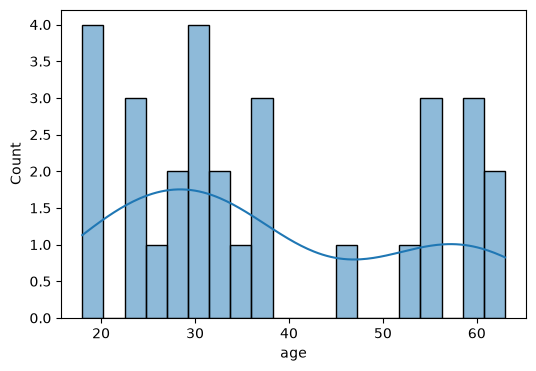

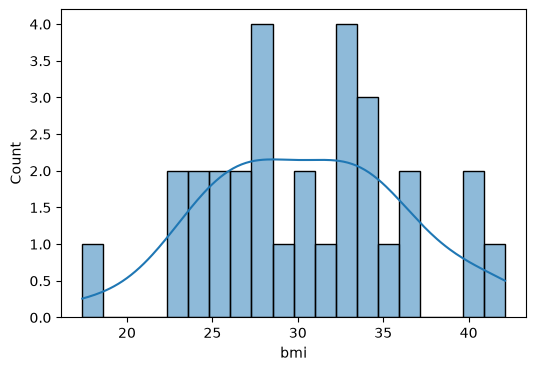

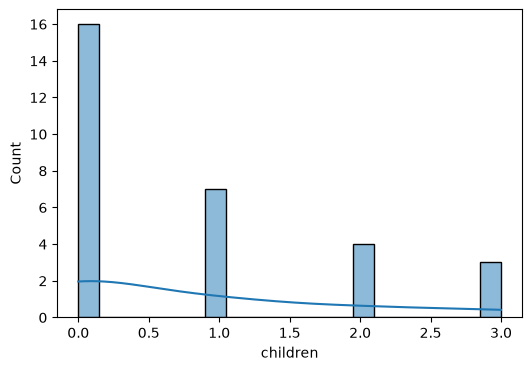

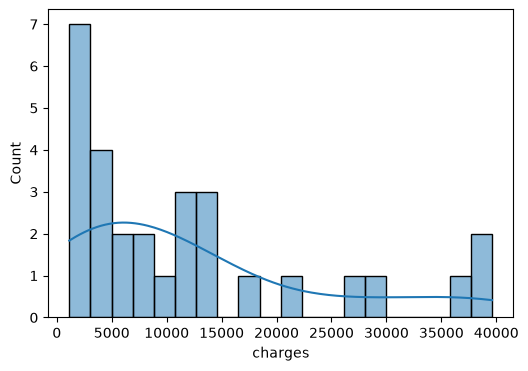

In [21]:
numeric_columns = ['age', 'bmi', 'children', 'charges']
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(data[col],kde=True, bins = 20)

<Axes: xlabel='children', ylabel='count'>

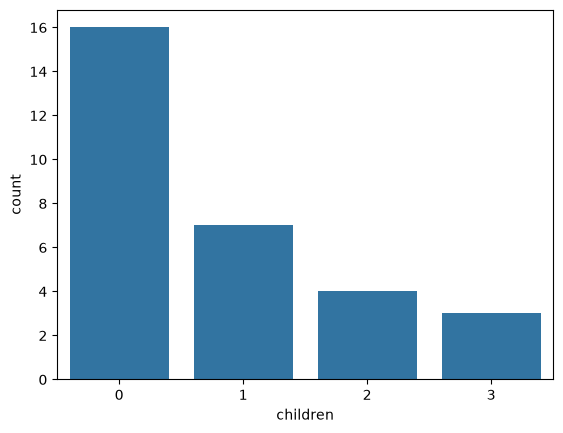

In [22]:
sns.countplot(x= data['children']) 

<Axes: xlabel='count', ylabel='sex'>

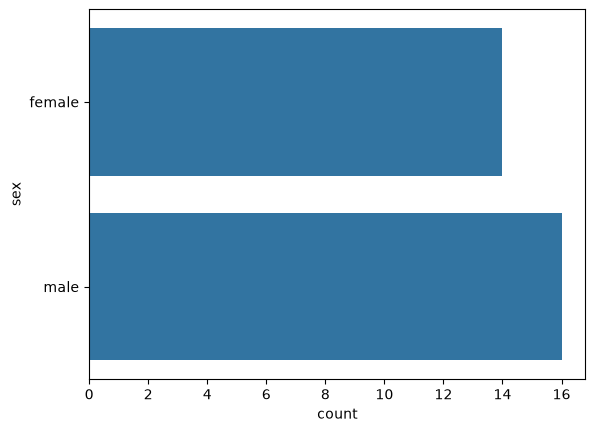

In [23]:
sns.countplot(y= data['sex'])

<Axes: >

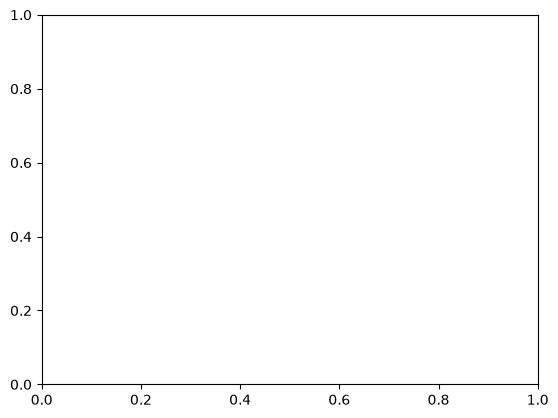

In [24]:
sns.countplot(z= data['smoker'])

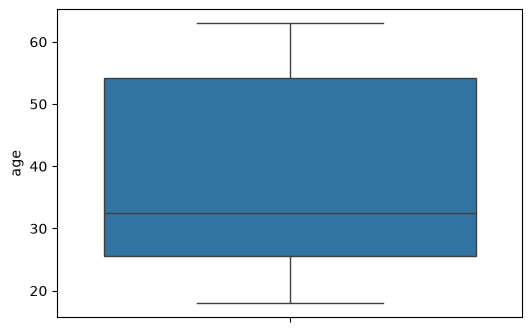

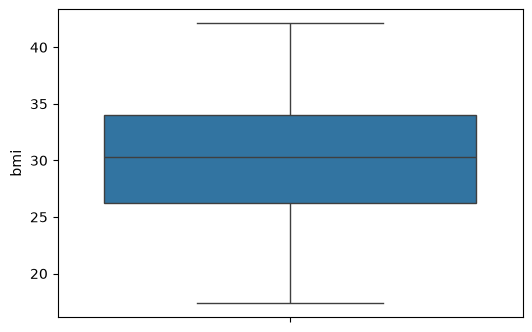

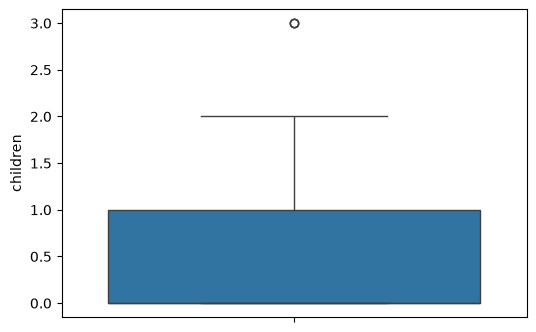

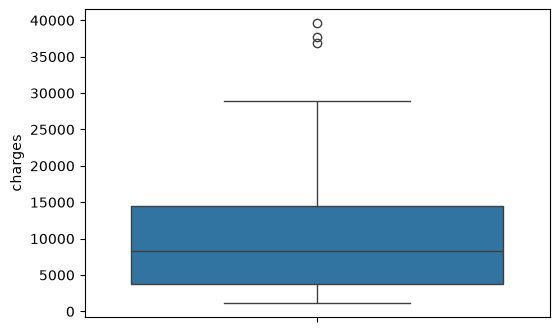

In [25]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(data[col])

<Axes: >

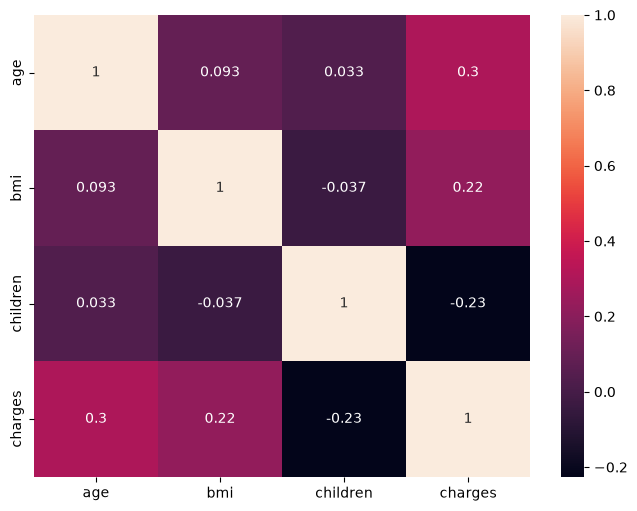

In [26]:
plt.figure(figsize=(8,6))
sns.heatmap(data.corr(numeric_only=True), annot=True)

#DATA CLEANING AND PREPROCESSING

In [54]:
data_cleaned= data.copy()

In [55]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.48200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [56]:
data_cleaned.shape

(30, 7)

In [57]:
data_cleaned.drop_duplicates(inplace=True)

In [58]:
data_cleaned.shape

(30, 7)

In [59]:
data_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     1
dtype: int64

In [60]:
data_cleaned.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [61]:
data_cleaned['sex'].value_counts()

sex
male      16
female    14
Name: count, dtype: int64

In [62]:
data_cleaned['sex'] = data_cleaned['sex'].map({'male':0, 'female':1})

In [63]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.48200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [64]:
data_cleaned['smoker'].value_counts()

smoker
no     24
yes     6
Name: count, dtype: int64

In [65]:
data_cleaned['smoker']=data_cleaned['smoker'].map({"yes":0, "no":1})

In [66]:
data_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,southwest,16884.92400
1,18,0,33.770,1,1,southeast,1725.55230
2,28,0,33.000,3,1,southeast,4449.48200
3,33,0,22.705,0,1,northwest,21984.47061
4,32,0,28.880,0,1,northwest,3866.85520


In [67]:
data_cleaned.rename(columns={'sex':'gender'}, inplace=True)

In [68]:
data_cleaned.head()

,age,gender,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,southwest,16884.92400
1,18,0,33.770,1,1,southeast,1725.55230
2,28,0,33.000,3,1,southeast,4449.48200
3,33,0,22.705,0,1,northwest,21984.47061
4,32,0,28.880,0,1,northwest,3866.85520


In [69]:
data_cleaned['region'].value_counts()

region
southeast    9
southwest    7
northwest    7
northeast    7
Name: count, dtype: int64

In [70]:
data_cleaned = pd.get_dummies(data_cleaned, columns=['region'], drop_first=True)

In [71]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,0,16884.92400,False,False,True
1,18,0,33.770,1,1,1725.55230,False,True,False
2,28,0,33.000,3,1,4449.48200,False,True,False
3,33,0,22.705,0,1,21984.47061,True,False,False
4,32,0,28.880,0,1,3866.85520,True,False,False


In [72]:
data_cleaned.shape

(30, 9)

In [73]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,0,16884.92400,False,False,True
1,18,0,33.770,1,1,1725.55230,False,True,False
2,28,0,33.000,3,1,4449.48200,False,True,False
3,33,0,22.705,0,1,21984.47061,True,False,False
4,32,0,28.880,0,1,3866.85520,True,False,False


In [74]:
data_cleaned = data_cleaned.dropna()

In [75]:
data_cleaned.shape

(29, 9)

In [76]:
data_cleaned = data_cleaned.astype(int)

In [77]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,0,16884,0,0,1
1,18,0,33,1,1,1725,0,1,0
2,28,0,33,3,1,4449,0,1,0
3,33,0,22,0,1,21984,1,0,0
4,32,0,28,0,1,3866,1,0,0


# Feature Engineering and Extraction

In [78]:
data_cleaned['bmi category'] = pd.cut(data_cleaned['bmi'], 
bins=[0, 18.5, 24.9, 29.9, np.inf], 
labels=['Underweight', 'Normal weight', 'Overweight', 'Obesity'])

In [79]:
data_cleaned.shape

(29, 10)

In [81]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi category
0,19,1,27,0,0,16884,0,0,1,Overweight
1,18,0,33,1,1,1725,0,1,0,Obesity
2,28,0,33,3,1,4449,0,1,0,Obesity
3,33,0,22,0,1,21984,1,0,0,Normal weight
4,32,0,28,0,1,3866,1,0,0,Overweight


In [82]:
data_cleaned = pd.get_dummies(data_cleaned, columns=['bmi category'], drop_first=True)

In [83]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi category_Normal weight,bmi category_Overweight,bmi category_Obesity
0,19,1,27,0,0,16884,0,0,1,False,True,False
1,18,0,33,1,1,1725,0,1,0,False,False,True
2,28,0,33,3,1,4449,0,1,0,False,False,True
3,33,0,22,0,1,21984,1,0,0,True,False,False
4,32,0,28,0,1,3866,1,0,0,False,True,False


In [84]:
data_cleaned = data_cleaned.astype(int)

In [85]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi category_Normal weight,bmi category_Overweight,bmi category_Obesity
0,19,1,27,0,0,16884,0,0,1,0,1,0
1,18,0,33,1,1,1725,0,1,0,0,0,1
2,28,0,33,3,1,4449,0,1,0,0,0,1
3,33,0,22,0,1,21984,1,0,0,1,0,0
4,32,0,28,0,1,3866,1,0,0,0,1,0


In [89]:
data_cleaned.columns

Index(['age', 'gender', 'bmi', 'children', 'smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi category_Normal weight', 'bmi category_Overweight',
       'bmi category_Obesity'],
      dtype='object')

In [86]:
from sklearn.preprocessing import StandardScaler
columns = ['age', 'bmi', 'children']
scaler = StandardScaler()
data_cleaned[columns] = scaler.fit_transform(data_cleaned[columns])

In [87]:
data_cleaned.head()

,age,gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi category_Normal weight,bmi category_Overweight,bmi category_Obesity
0,-1.234378,1,-0.473380,-0.754594,0,16884,0,0,1,0,1,0
1,-1.300424,0,0.582621,0.240098,1,1725,0,1,0,0,0,1
2,-0.639963,0,0.582621,2.229482,1,4449,0,1,0,0,0,1
3,-0.309733,0,-1.353381,-0.754594,1,21984,1,0,0,1,0,0
4,-0.375779,0,-0.297380,-0.754594,1,3866,1,0,0,0,1,0


In [91]:
data_cleaned['charges'].corr(data_cleaned['age'])

np.float64(0.2969110310171934)

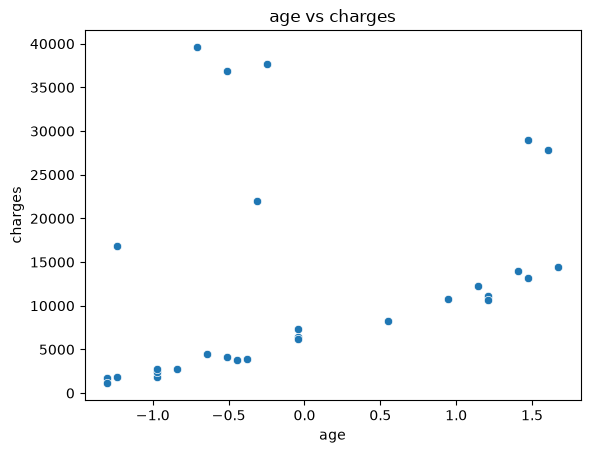

In [92]:
sns.scatterplot(x=data_cleaned['age'], y=data_cleaned['charges'])
plt.title('age vs charges')
plt.show()

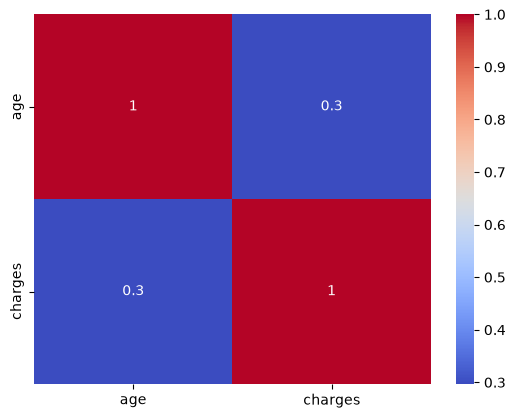

In [96]:
sns.heatmap(
    data_cleaned[['age','charges']].corr(),
    annot = True,
    cmap='coolwarm'
)
plt.show()

In [98]:
from scipy.stats import pearsonr
# PEARSON CORRELATION CALCULATION
#----------------------------------
#List of feature to checkagainst target
selected_features = [
    'age', 'gender', 'bmi', 'children', 'smoker', 'charges', 'region_northwest',
    'region_southeast', 'region_southwest', 'bmi category_Normal weight', 
    'bmi category_Overweight', 'bmi category_Obesity'
]
correlations = {
    feature: pearsonr(data_cleaned[feature], data_cleaned['charges'])[0] 
    for feature in selected_features
}
correlations_data_cleaned = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlations_data_cleaned.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
5,charges,1.000000
0,age,0.296911
1,gender,0.237641
2,bmi,0.220107
11,bmi category_Obesity,0.135141
7,region_southeast,0.010862
8,region_southwest,-0.009740
6,region_northwest,-0.016824
10,bmi category_Overweight,-0.028970
9,bmi category_Normal weight,-0.072804


In [99]:
cat_features = {
    'age', 'gender', 'bmi', 'children', 'smoker', 'charges', 'region_northwest',
    'region_southeast', 'region_southwest', 'bmi category_Normal weight', 
    'bmi category_Overweight', 'bmi category_Obesity'
}

In [106]:
from scipy.stats import chi2_contingency

alpha = 0.05
data_cleaned['charges bin'] = pd.qcut(data_cleaned['charges'], q=4, labels=False)
chi2_results = {}

for column in cat_features:
    contingency = pd.crosstab(data_cleaned[column], data_cleaned['charges bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = "Reject Null(Keep Feature)" if p_val < alpha else "Accept Null(Drop Feature)"
    chi2_results[column] = {
        'Chi2_Statistic': chi2_stat,
        'p-value': p_val,
        'Decision': decision
    }

chi2_results_data_cleaned = pd.DataFrame(chi2_results).T
chi2_results_data_cleaned = chi2_results_data_cleaned.sort_values(by='p-value')
chi2_results_data_cleaned

,Chi2_Statistic,p-value,Decision
smoker,18.988095,0.000275,Reject Null(Keep Feature)
gender,8.332568,0.039616,Reject Null(Keep Feature)
age,74.830357,0.056708,Accept Null(Drop Feature)
children,12.408535,0.191245,Accept Null(Drop Feature)
bmi category_Overweight,3.390602,0.33523,Accept Null(Drop Feature)
bmi,57.741071,0.338765,Accept Null(Drop Feature)
charges,87.0,0.389713,Accept Null(Drop Feature)
region_northwest,2.377435,0.497849,Accept Null(Drop Feature)
bmi category_Obesity,2.039371,0.564276,Accept Null(Drop Feature)
bmi category_Normal weight,1.967857,0.579105,Accept Null(Drop Feature)


In [107]:
final_data = data_cleaned[[ 'age', 'bmi', 'children', 'charges', 'region_northwest',
    'region_southeast', 'region_southwest', 'bmi category_Normal weight', 
    'bmi category_Overweight', 'bmi category_Obesity'
]]

In [111]:
final_data

,age,bmi,children,charges,region_northwest,region_southeast,region_southwest,bmi category_Normal weight,bmi category_Overweight,bmi category_Obesity
0,-1.234378,-0.473380,-0.754594,16884,0,0,1,0,1,0
1,-1.300424,0.582621,0.240098,1725,0,1,0,0,0,1
2,-0.639963,0.582621,2.229482,4449,0,1,0,0,0,1
3,-0.309733,-1.353381,-0.754594,21984,1,0,0,1,0,0
4,-0.375779,-0.297380,-0.754594,3866,1,0,0,0,1,0
5,-0.441825,-0.825380,-0.754594,3756,0,1,0,0,1,0
6,0.548865,0.582621,0.240098,8240,0,1,0,0,0,1
7,-0.045549,-0.473380,2.229482,7281,1,0,0,0,1,0
8,-0.045549,-0.121379,1.234790,6406,0,0,0,0,1,0
9,1.473510,-0.825380,-0.754594,28923,1,0,0,0,1,0
